# EDA: Oxford-IIIT Pet - семантическая сегментация

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from functools import partial
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'notebooks'))
from eda_helpers import inspect_image, inspect_mask, show_masks

RAW = ROOT / 'data/raw'
IMAGE_DIR = RAW / 'images'
MASK_DIR = RAW / 'annotations/trimaps'
OUTPUT = ROOT / 'data/processed'
TARGET_DIR = OUTPUT / 'pets_masks'
TARGET_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 100})
assert IMAGE_DIR.exists() and MASK_DIR.exists(), 'Нужны распакованные исходные архивы Oxford'

## 1. Структура каталогов

Изображения - JPEG, маски - PNG, метаданные - TXT. Отделяем служебные файлы AppleDouble по имени и сигнатуре.

In [2]:
image_paths = sorted(IMAGE_DIR.glob('*.jpg'))
all_png_paths = sorted(MASK_DIR.glob('*.png'))
sidecars = [path for path in all_png_paths if path.name.startswith('._') and path.read_bytes()[:4] == bytes.fromhex('00051607')]
sidecar_set = set(sidecars)
mask_paths = [path for path in all_png_paths if path not in sidecar_set]
print('images/:', [path.name for path in image_paths[:3]])
print('annotations/:', [path.name for path in (RAW / 'annotations').glob('*.txt')])
print('trimaps/:', [path.name for path in mask_paths[:3]])
print('Служебных AppleDouble:', len(sidecars))

images/: ['Abyssinian_1.jpg', 'Abyssinian_10.jpg', 'Abyssinian_100.jpg']
annotations/: ['list.txt', 'test.txt', 'trainval.txt']
trimaps/: ['Abyssinian_1.png', 'Abyssinian_10.png', 'Abyssinian_100.png']
Служебных AppleDouble: 7390


## 2. Количество изображений, масок и метаданных

Читаем официальный список и поля: ID, глобальная порода, вид, порода внутри вида.

In [3]:
columns = ['id', 'class_id', 'species', 'breed_id']
metadata = pd.read_csv(RAW / 'annotations/list.txt', sep=r'\s+', comment='#', names=columns)
metadata['breed'] = metadata.id.str.rsplit('_', n=1).str[0]
trainval_metadata = pd.read_csv(RAW / 'annotations/trainval.txt', sep=r'\s+', comment='#', names=columns)
test_metadata = pd.read_csv(RAW / 'annotations/test.txt', sep=r'\s+', comment='#', names=columns)
official = pd.concat([trainval_metadata.assign(official_split='trainval'), test_metadata.assign(official_split='test')])
assert metadata.id.is_unique and official.id.is_unique
metadata = metadata.merge(official[['id', 'official_split']], on='id', validate='one_to_one')
display(pd.Series({'JPEG': len(image_paths), 'PNG masks': len(mask_paths), 'metadata': len(metadata)}).to_frame('count'))
display(metadata.head())

,count
JPEG,7390
PNG masks,7390
metadata,7349


,id,class_id,species,breed_id,breed,official_split
0,Abyssinian_100,1,1,1,Abyssinian,trainval
1,Abyssinian_101,1,1,1,Abyssinian,trainval
2,Abyssinian_102,1,1,1,Abyssinian,trainval
3,Abyssinian_103,1,1,1,Abyssinian,trainval
4,Abyssinian_104,1,1,1,Abyssinian,trainval


## 3. Соответствие изображений и масок

Проверяем пары по базовому имени и сверяем их с официальными метаданными.

In [4]:
image_ids = {path.stem for path in image_paths}
mask_ids = {path.stem for path in mask_paths}
metadata_ids = set(metadata.id)
inventory = pd.DataFrame({'id': sorted(image_ids | mask_ids | metadata_ids)})
inventory['has_image'] = inventory.id.isin(image_ids)
inventory['has_mask'] = inventory.id.isin(mask_ids)
inventory['has_metadata'] = inventory.id.isin(metadata_ids)
display(inventory[['has_image', 'has_mask', 'has_metadata']].value_counts().to_frame('count'))
print('Отсутствует image:', len(metadata_ids - image_ids))
print('Отсутствует mask:', len(metadata_ids - mask_ids))
display(inventory[~inventory.has_metadata].head())
assert metadata_ids <= image_ids & mask_ids

count
has_image has_mask has_metadata       
True      True     True           7349
                   False            41

Отсутствует image: 0
Отсутствует mask: 0


,id,has_image,has_mask,has_metadata
136,Abyssinian_34,True,True,False
181,Abyssinian_82,True,True,False
612,Bombay_11,True,True,False
692,Bombay_189,True,True,False
694,Bombay_190,True,True,False


**Мини-вывод.** Каждая из 7349 официальных записей имеет изображение и маску. Ещё 41 пара находится вне официального списка; в train/validation/test её не добавляем.

## 4. Читаемость JPEG и PNG

In [5]:
with ThreadPoolExecutor(max_workers=4) as workers:
    image_audit = pd.DataFrame(workers.map(partial(inspect_image, mask_dir=MASK_DIR), image_paths))
    mask_audit = pd.DataFrame(workers.map(inspect_mask, mask_paths))
print('Нечитаемых JPEG:', (~image_audit.readable).sum())
print('Нечитаемых PNG:', (~mask_audit.mask_readable).sum())
display(image_audit[~image_audit.readable])
display(mask_audit[~mask_audit.mask_readable])
pets = metadata.merge(image_audit, on='id', how='left', validate='one_to_one')
pets = pets.merge(mask_audit, on='id', how='left', validate='one_to_one')

Нечитаемых JPEG: 0
Нечитаемых PNG: 0


,id,file,bytes,sha256,format,mode,width,height,aspect,megapixels,pixel_sha256,readable,phash,luminance_mean,luminance_std,foreground_luminance_mean,foreground_luminance_std,background_luminance_mean,background_luminance_std


,id,mask_file,mask_format,mask_mode,mask_readable,mask_width,mask_height,mask_values,invalid_values,pixels_1,pixels_2,pixels_3,foreground_fraction,uncertain_fraction,empty_foreground,centroid_x,centroid_y,bbox_width,bbox_height


## 5. Исходная кодировка масок

Сверяем значения пикселей и описание в README архива.

In [6]:
display(mask_audit.groupby(['mask_format', 'mask_mode', 'mask_values']).size().to_frame('masks'))
print('Пикселей с недопустимыми значениями:', mask_audit.invalid_values.sum())
print((RAW / 'annotations/README').read_text().split('Pixel Annotations:')[1].splitlines()[0])

masks
mask_format mask_mode mask_values       
PNG         L         1,2,3         7367
                      2               23

Пикселей с недопустимыми значениями: 0
 1: Foreground 2:Background 3: Not classified


Исходные значения: 1 — foreground, 2 — background, 3 — not classified

## 6. Определение вида по породе

In [7]:
breed_mapping = metadata.groupby(['class_id', 'breed']).agg(species=('species', 'first'), species_count=('species', 'nunique'))
display(breed_mapping)
assert len(breed_mapping) == 37 and breed_mapping.species_count.eq(1).all()
assert set(metadata.species) == {1, 2}
assert metadata.id.str[0].str.isupper().eq(metadata.species.eq(1)).all()

,,species,species_count
class_id,breed,,
1,Abyssinian,1,1
2,american_bulldog,2,1
3,american_pit_bull_terrier,2,1
4,basset_hound,2,1
5,beagle,2,1
6,Bengal,1,1
7,Birman,1,1
8,Bombay,1,1
9,boxer,2,1


Для преобразования используем поле SPECIES

## 7. Объединение пород в Cat и Dog


In [8]:
pets['species_name'] = pets.species.map({1: 'cat', 2: 'dog'})
display(pets.groupby('species_name').agg(breeds=('class_id', 'nunique'), images=('id', 'size')))

,breeds,images
species_name,,
cat,12,2371
dog,25,4978


12 пород кошек объединены в cat, 25 пород собак - в dog.

## 8. Целевые маски

In [9]:
for row in pets.itertuples():
    if not (row.readable and row.mask_readable and row.invalid_values == 0):
        continue
    with Image.open(MASK_DIR / f'{row.id}.png') as image:
        source_mask = np.asarray(image)
    target_mask = np.full(source_mask.shape, 255, dtype=np.uint8)
    target_mask[source_mask == 2] = 0
    target_mask[source_mask == 1] = row.species
    assert set(np.unique(target_mask)) <= {0, 1, 2, 255}
    assert target_mask.shape == (int(row.height), int(row.width))
    Image.fromarray(target_mask).save(TARGET_DIR / f'{row.id}.png')
print('Преобразовано масок:', len(list(TARGET_DIR.glob('*.png'))))

Преобразовано масок: 7349


## 9. Баланс кошек и собак

Считаем изображения по видам и официальным выборкам.

official_split,test,trainval
species_name,,
cat,1183,1188
dog,2486,2492


,fraction
species_name,
cat,0.322629
dog,0.677371


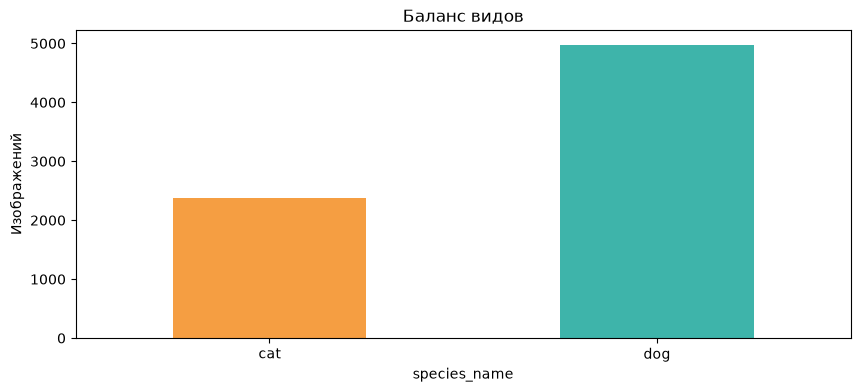

In [10]:
species_counts = pets.species_name.value_counts().reindex(['cat', 'dog'])
display(pd.crosstab(pets.species_name, pets.official_split))
display((species_counts / len(pets)).rename('fraction').to_frame())
species_counts.plot.bar(color=['#f59e42', '#3eb4aa'], rot=0)
plt.ylabel('Изображений')
plt.title('Баланс видов')
plt.show()

Кошек 2371 (32,3%), собак 4978 (67,7%)

## 10. Размеры, пропорции и разрешения

Используем исходные размеры официальных изображений; megapixels = width × height / 1e6.

,count,mean,std,min,5%,50%,95%,max
width,7349.0,437.237447,115.775876,114.000000,281.0000,500.000000,500.000000,3264.000000
height,7349.0,391.387264,109.394560,103.000000,225.0000,375.000000,500.000000,2606.000000
aspect,7349.0,1.172173,0.329474,0.420000,0.6660,1.333333,1.506024,2.564103
megapixels,7349.0,0.175208,0.157327,0.014111,0.0675,0.167500,0.231000,7.990272


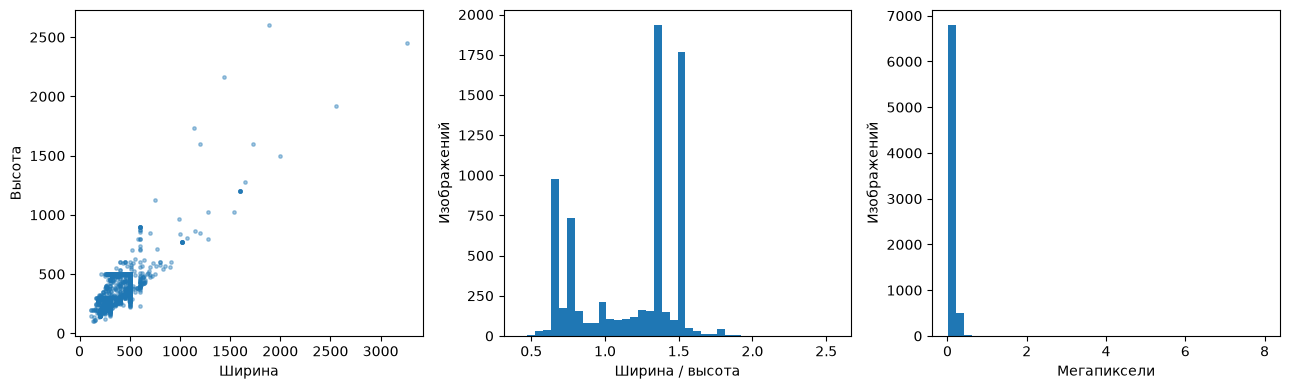

In [11]:
display(pets[['width', 'height', 'aspect', 'megapixels']].describe(percentiles=[.05, .5, .95]).T)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].scatter(pets.width, pets.height, s=6, alpha=.4)
axes[0].set(xlabel='Ширина', ylabel='Высота')
axes[1].hist(pets.aspect, bins=40)
axes[1].set(xlabel='Ширина / высота', ylabel='Изображений')
axes[2].hist(pets.megapixels, bins=40)
axes[2].set(xlabel='Мегапиксели', ylabel='Изображений')
plt.tight_layout()
plt.show()

Нужен ресайз

## 11. Совпадение размеров image и mask

Сравниваем размеры всех официальных пар.

In [12]:
pets['size_match'] = pets.width.eq(pets.mask_width) & pets.height.eq(pets.mask_height)
display(pets.loc[~pets.size_match, ['id', 'width', 'height', 'mask_width', 'mask_height']])
print('Совпадают размеры:', pets.size_match.sum(), 'из', len(pets))
pets['usable'] = pets.readable & pets.mask_readable & pets.size_match & pets.invalid_values.eq(0)
assert pets.size_match.all()

,id,width,height,mask_width,mask_height


Совпадают размеры: 7349 из 7349


## 12. Доли пикселей целевых классов

Суммируем пиксели на исходных разрешениях; отдельно считаем доли среди всех и только supervised-пикселей.

,pixels,fraction_all,fraction_supervised
background,758472669,0.589057,0.666190
cat,137533110,0.106813,0.120800
dog,242517696,0.188348,0.213011
ignore,149081782,0.115782,NaN


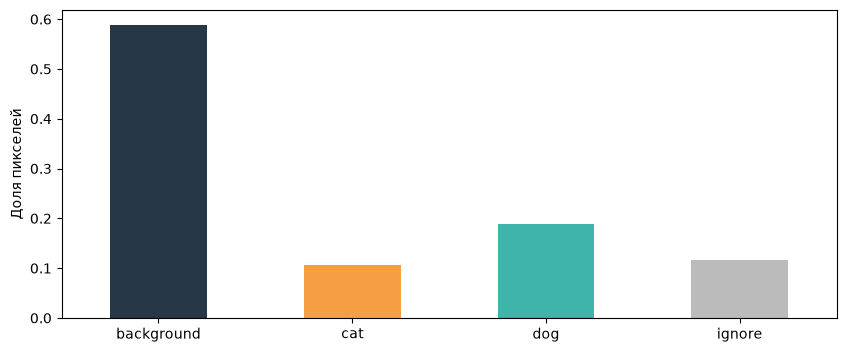

In [13]:
pixel_counts = pd.Series({
    'background': int(pets.pixels_2.sum()),
    'cat': int(pets.loc[pets.species.eq(1), 'pixels_1'].sum()),
    'dog': int(pets.loc[pets.species.eq(2), 'pixels_1'].sum()),
    'ignore': int(pets.pixels_3.sum()),
})
pixel_statistics = pixel_counts.to_frame('pixels')
pixel_statistics['fraction_all'] = pixel_counts / pixel_counts.sum()
pixel_statistics['fraction_supervised'] = pixel_counts / (pixel_counts.sum() - pixel_counts['ignore'])
pixel_statistics.loc['ignore', 'fraction_supervised'] = np.nan
display(pixel_statistics)
pixel_statistics.fraction_all.plot.bar(color=['#263747', '#f59e42', '#3eb4aa', '#bbbbbb'], rot=0)
plt.ylabel('Доля пикселей')
plt.show()

## 13. Относительная площадь животного


,count,mean,std,min,5%,50%,95%,max
species_name,,,,,,,,
cat,2371.0,0.328177,0.164151,0.0,0.102026,0.307134,0.628107,0.940217
dog,4978.0,0.286235,0.162741,0.0,0.068232,0.258606,0.591661,0.946795


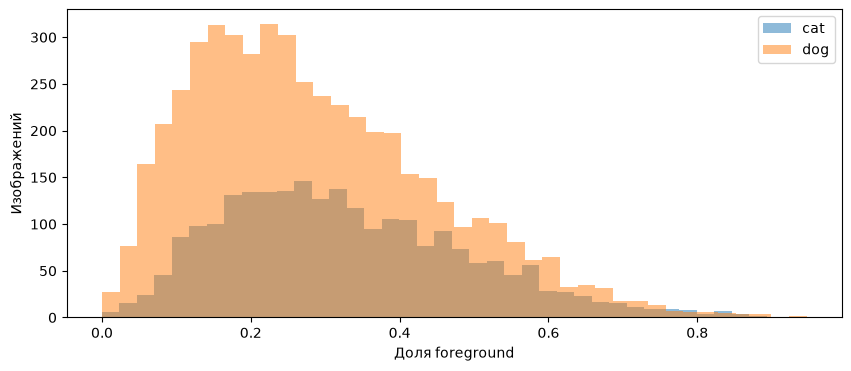

In [14]:
display(pets.groupby('species_name').foreground_fraction.describe(percentiles=[.05, .5, .95]))
for species in ['cat', 'dog']:
    plt.hist(pets.loc[pets.species_name.eq(species), 'foreground_fraction'], bins=40, alpha=.5, label=species)
plt.xlabel('Доля foreground')
plt.ylabel('Изображений')
plt.legend()
plt.show()

## 14. Очень маленькие и большие объекты

,id,species_name,foreground_fraction,width,height
3578,staffordshire_bull_terrier_19,dog,0.010994,500,352
3984,basset_hound_197,dog,0.011716,500,402
6148,pomeranian_89,dog,0.946795,375,500
5542,keeshond_83,dog,0.946629,500,375


Непустых объектов <1%: 0
Объектов >90%: 5


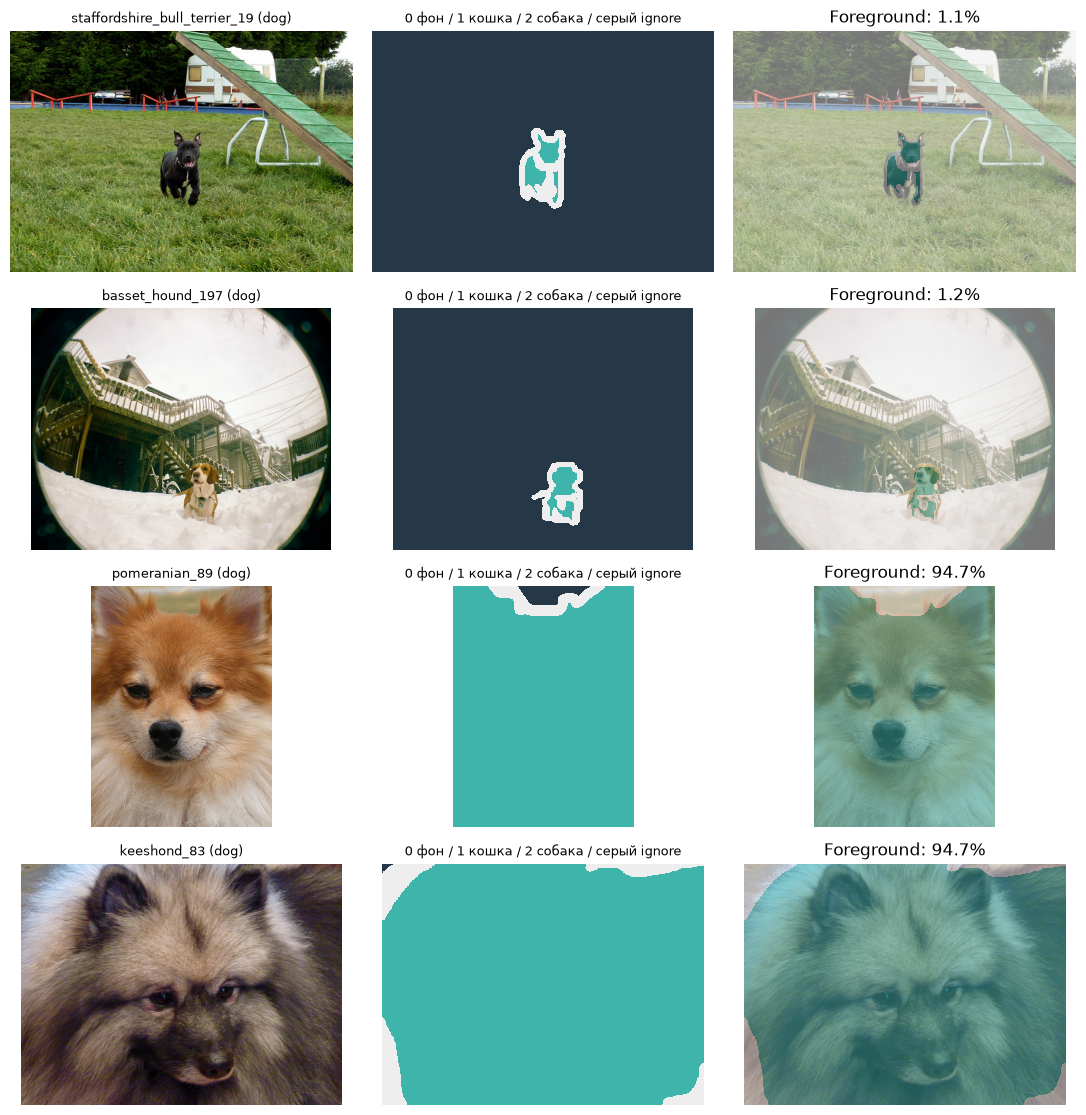

In [15]:
nonempty = pets[pets.foreground_fraction > 0]
smallest = nonempty.nsmallest(2, 'foreground_fraction')
largest = pets.nlargest(2, 'foreground_fraction')
display(pd.concat([smallest, largest])[['id', 'species_name', 'foreground_fraction', 'width', 'height']])
print('Непустых объектов <1%:', nonempty.foreground_fraction.lt(.01).sum())
print('Объектов >90%:', pets.foreground_fraction.gt(.9).sum())
show_masks(list(smallest.id) + list(largest.id), pets, IMAGE_DIR, TARGET_DIR)

## 15. Пустые маски и аномалии

Выделяем маски без достоверного foreground и проверяем примеры, где животное видно в исходнике.

,id,official_split,pixels_1,pixels_2,pixels_3
1404,saint_bernard_108,trainval,0,166500,0
2407,Egyptian_Mau_162,trainval,0,7990272,0
2410,Egyptian_Mau_165,trainval,0,4915200,0
2437,Egyptian_Mau_196,trainval,0,4914916,0
2833,leonberger_18,trainval,0,131500,0
2889,miniature_pinscher_14,trainval,0,187500,0
3246,saint_bernard_15,trainval,0,187500,0
4773,Egyptian_Mau_20,test,0,3110400,0
5370,japanese_chin_199,test,0,187500,0
5538,keeshond_7,test,0,166500,0


Пустых foreground во всём архиве: 23
Пустых foreground в официальном списке: 14
Масок с недопустимыми значениями: 0


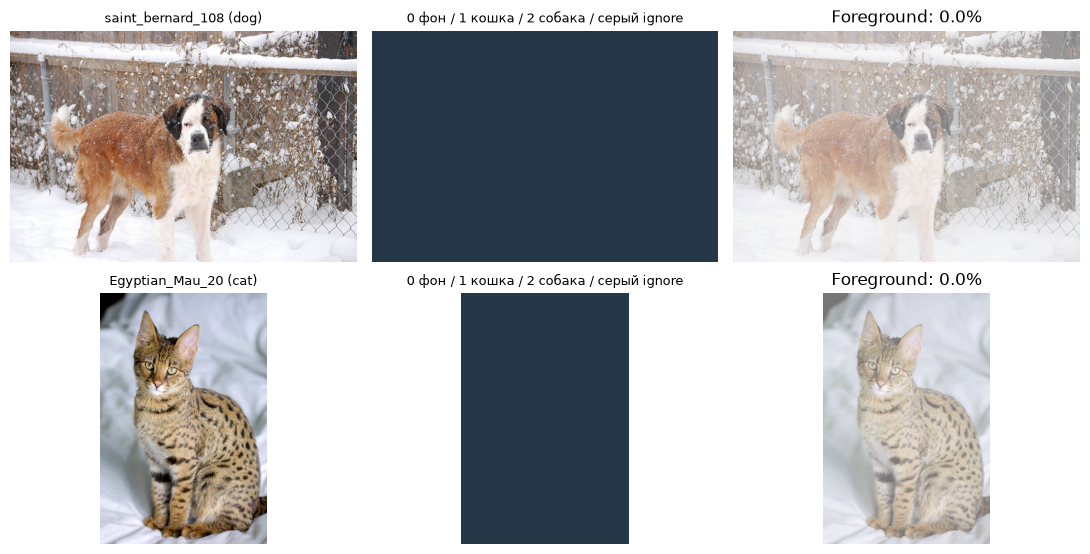

In [16]:
empty_masks = pets[pets.empty_foreground]
display(empty_masks[['id', 'official_split', 'pixels_1', 'pixels_2', 'pixels_3']])
print('Пустых foreground во всём архиве:', mask_audit.empty_foreground.sum())
print('Пустых foreground в официальном списке:', len(empty_masks))
print('Масок с недопустимыми значениями:', pets.invalid_values.gt(0).sum())
show_masks(['saint_bernard_108', 'Egyptian_Mau_20'], pets, IMAGE_DIR, TARGET_DIR)

## 16. Примеры изображений, масок и наложений

Для каждого вида показываем несколько исходников, целевые маски и overlay.

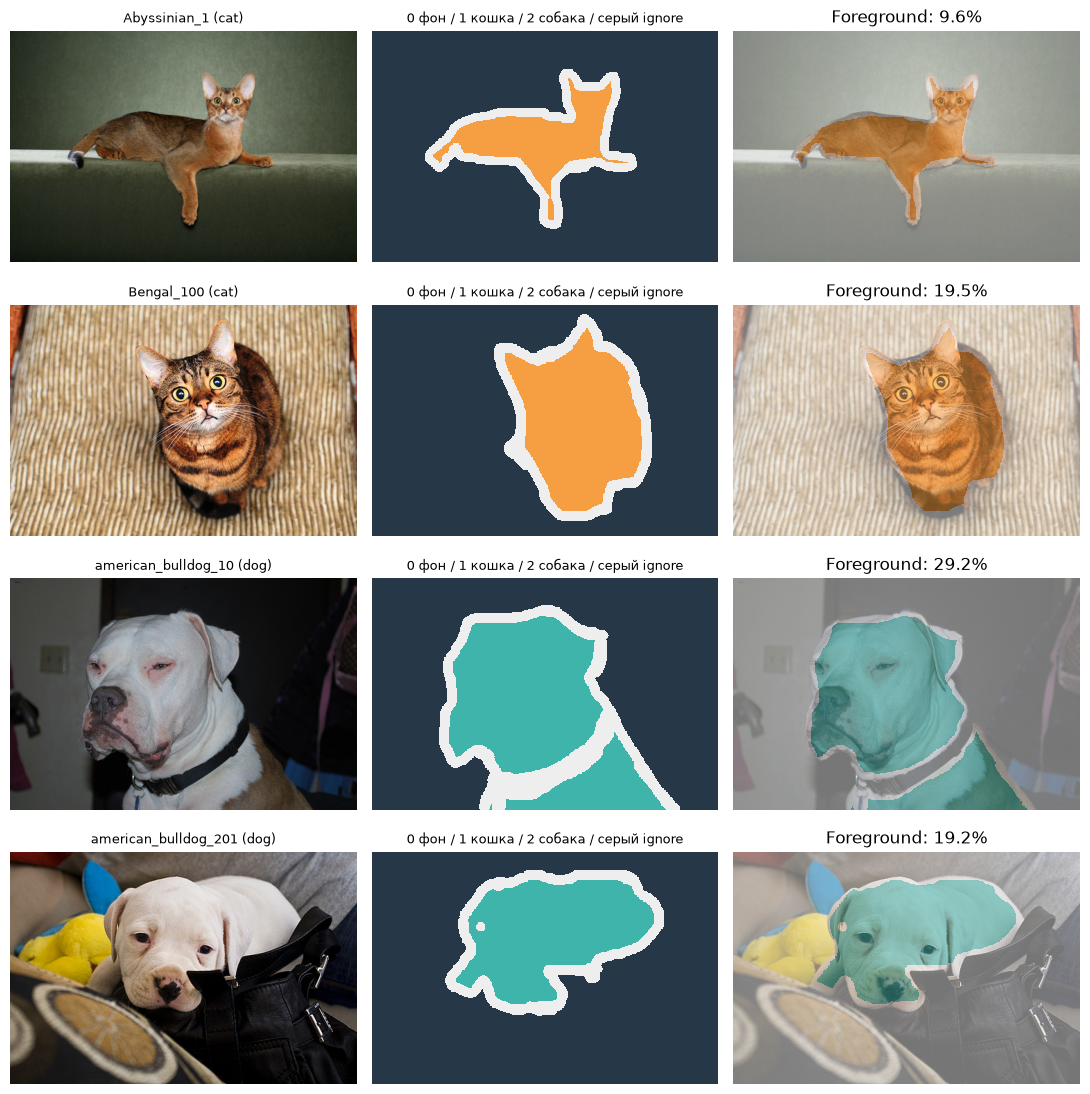

In [17]:
example_ids = ['Abyssinian_1', 'Bengal_100', 'american_bulldog_10', 'american_bulldog_201']
show_masks(example_ids, pets, IMAGE_DIR, TARGET_DIR)

## 17. Положение, освещение и фоны



foreground_fraction           centroid_x           centroid_y  \
                            mean    median       mean    median       mean   
species_name                                                                 
cat                     0.328177  0.307134   0.505156  0.504268   0.548312   
dog                     0.286235  0.258606   0.499367  0.499076   0.520232   

                       luminance_mean             background_luminance_mean  \
                median           mean      median                      mean   
species_name                                                                  
cat           0.553515     115.015479  114.646739                117.842688   
dog           0.521117     115.688479  115.223274                116.880464   

                         background_luminance_std             
                  median                     mean     median  
species_name                                                  
cat           117.064971                43.924414  43.627065  
dog           115.444972                45.143062  44.553255

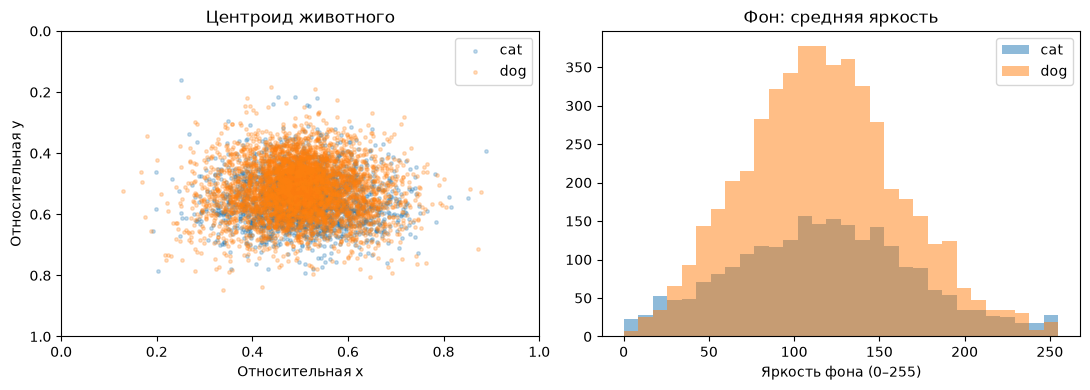

In [18]:
display(pets.groupby('species_name')[['foreground_fraction', 'centroid_x', 'centroid_y',
                                     'luminance_mean', 'background_luminance_mean', 'background_luminance_std']].agg(['mean', 'median']))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for species in ['cat', 'dog']:
    part = pets[pets.species_name.eq(species)]
    axes[0].scatter(part.centroid_x, part.centroid_y, s=6, alpha=.25, label=species)
    axes[1].hist(part.background_luminance_mean.dropna(), bins=30, alpha=.5, label=species)
axes[0].set(xlabel='Относительная x', ylabel='Относительная y', xlim=(0, 1), ylim=(1, 0), title='Центроид животного')
axes[1].set(xlabel='Яркость фона (0–255)', title='Фон: средняя яркость')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 18. Официальные trainval/test

In [19]:
trainval_ids = set(trainval_metadata.id)
test_ids = set(test_metadata.id)
assert not trainval_ids & test_ids
assert trainval_ids | test_ids == metadata_ids
pd.testing.assert_frame_equal(
    metadata[columns].sort_values('id').reset_index(drop=True),
    official[columns].sort_values('id').reset_index(drop=True),
)
display(pets.groupby(['official_split', 'species_name']).size().unstack())

species_name,cat,dog
official_split,,
test,1183,2486
trainval,1188,2492


## 19. Стратегия выделения validation

Из trainval выделим около 20% под validation:

1. Сначала объединим точные и визуально близкие кандидаты в группы.
2. Исключим из trainval группы, связанные с официальным test.
3. Применим `StratifiedGroupKFold(5, shuffle=True, random_state=42)` со стратификацией по породам.
4. Первый fold станет validation, остальные - train. Сам test не меняем.

Код разделения идёт в пункте 22 после расчёта хешей.

## 20. Пересечения по именам и содержимому

SHA-256 считается отдельно по байтам JPEG и по декодированному RGB с учётом формы массива; хеши получены при полном аудите в пункте 4.

In [20]:
print('Общие имена trainval/test:', len(trainval_ids & test_ids))
for key in ['sha256', 'pixel_sha256']:
    trainval_hashes = set(pets.loc[pets.official_split.eq('trainval'), key])
    test_hashes = set(pets.loc[pets.official_split.eq('test'), key])
    print(key, 'общих значений:', len(trainval_hashes & test_hashes))

Общие имена trainval/test: 0
sha256 общих значений: 0
pixel_sha256 общих значений: 0


## 21. Точные и визуально близкие дубликаты

Точные совпадения ищем по SHA-256. Для близких кадров используем DCT pHash: 32×32 → 8×8, Hamming ≤6; DC-бит не участвует. Это кандидаты, а не доказательство идентичности животного.

Строк в группах одинаковых RGB: 59


,id,pixel_sha256
602,Bombay_100,8b1c6fd52428d185c8a723270ecd32fbd156bba7289120...
604,Bombay_102,b1782ee8751d806eb1732131077e0785002d6c460e8b76...
611,Bombay_109,c4843f76d234628d14fca19a87b30c36e7d554408fa7e7...
612,Bombay_11,8b1c6fd52428d185c8a723270ecd32fbd156bba7289120...
621,Bombay_118,cd6c91d497d517637c24d25961f838d2d0af3d0e0fd90a...
625,Bombay_121,570428413bb4ef4e0113c832eee7ca0df73b07240facbd...
629,Bombay_126,a0c2dff8e9b2cea97a04eb5860419856d33ba13b849370...
635,Bombay_131,8841551d26ebc0bfe58d8275edac08e57c2b259f1de561...
668,Bombay_164,6d14fc3a9d73e9e1987230f961f9e98deb784cc0e7c480...
689,Bombay_185,4e5f93a8dce98e695d6987c783aae5365302161d5b5ed5...


Perceptual-кандидатов: 82
Пар между trainval/test: 24


,id_a,id_b,distance,official_a,official_b
0,Abyssinian_11,Abyssinian_177,0,trainval,trainval
1,Abyssinian_122,Abyssinian_172,0,trainval,trainval
2,Abyssinian_151,Abyssinian_99,4,trainval,test
3,Abyssinian_24,Abyssinian_56,2,test,test
4,Abyssinian_40,Abyssinian_63,0,test,test
5,Abyssinian_5,Abyssinian_87,0,test,test
6,Birman_199,Birman_25,0,test,test
7,Bombay_100,Bombay_11,0,trainval,NaN
8,Bombay_100,Bombay_192,0,trainval,NaN
9,Bombay_102,Bombay_203,0,trainval,NaN


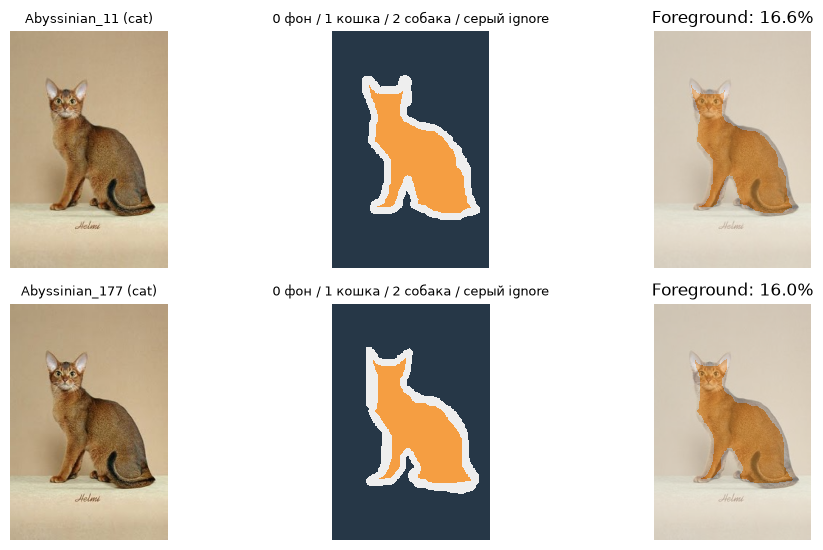

In [21]:
exact_images = image_audit[image_audit.duplicated('pixel_sha256', keep=False)]
print('Строк в группах одинаковых RGB:', len(exact_images))
display(exact_images[['id', 'pixel_sha256']].head(10))

hashed = image_audit[image_audit.readable].sort_values('id')
hash_ids = hashed.id.to_numpy()
hashes = np.array(hashed.phash, dtype=np.uint64)
popcount = np.array([value.bit_count() for value in range(256)], dtype=np.uint8)
pair_rows = []
for i in range(len(hashes) - 1):
    difference = np.bitwise_xor(hashes[i], hashes[i+1:])
    distances = popcount[difference.view(np.uint8).reshape(-1, 8)].sum(axis=1)
    for offset in np.flatnonzero(distances <= 6):
        j = i + 1 + offset
        pair_rows.append({'id_a': hash_ids[i], 'id_b': hash_ids[j], 'distance': int(distances[offset])})
pairs = pd.DataFrame(pair_rows, columns=['id_a', 'id_b', 'distance'])
lookup = pets.set_index('id').official_split
pairs['official_a'] = pairs.id_a.map(lookup)
pairs['official_b'] = pairs.id_b.map(lookup)
cross_official = pairs[pairs.official_a.notna() & pairs.official_b.notna() & pairs.official_a.ne(pairs.official_b)]
print('Perceptual-кандидатов:', len(pairs))
print('Пар между trainval/test:', len(cross_official))
display(pairs.head(10))
show_masks(['Abyssinian_11', 'Abyssinian_177'], pets, IMAGE_DIR, TARGET_DIR)

## 22. Влияние похожих фото и итоговое разбиение

In [22]:
valid = pets[pets.usable].copy()
parent = {image_id: image_id for image_id in valid.id}

def find_group(image_id):
    while parent[image_id] != image_id:
        parent[image_id] = parent[parent[image_id]]
        image_id = parent[image_id]
    return image_id

def join_groups(first, second):
    first, second = find_group(first), find_group(second)
    parent[max(first, second)] = min(first, second)

for key in ['sha256', 'pixel_sha256']:
    for _, group in valid.groupby(key):
        ids = list(group.id)
        for other in ids[1:]:
            join_groups(ids[0], other)
for row in pairs.itertuples():
    if row.id_a in parent and row.id_b in parent:
        join_groups(row.id_a, row.id_b)
valid['duplicate_group'] = valid.id.map(find_group)


In [23]:
test_groups = set(valid.loc[valid.official_split.eq('test'), 'duplicate_group'])
linked_to_test = valid.official_split.eq('trainval') & valid.duplicate_group.isin(test_groups)
valid['split'] = np.where(valid.official_split.eq('test'), 'test', 'train')
valid.loc[linked_to_test, 'split'] = 'excluded_test_overlap'
pool = valid[valid.official_split.eq('trainval') & ~linked_to_test]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
_, validation_indices = next(splitter.split(pool, pool.class_id, groups=pool.duplicate_group))
valid.loc[pool.iloc[validation_indices].index, 'split'] = 'validation'
pets = pets.merge(valid[['id', 'split', 'duplicate_group']], on='id', how='left', validate='one_to_one')
pets['split'] = pets.split.fillna('excluded_invalid')
display(pd.crosstab(pets.split, pets.species_name))


species_name,cat,dog
split,,
excluded_test_overlap,6,18
test,1183,2486
train,945,1981
validation,237,493


In [24]:
selected = pets[pets.split.isin(['train', 'validation', 'test'])]
for key in ['id', 'sha256', 'pixel_sha256', 'duplicate_group']:
    split_sets = {name: set(selected.loc[selected.split.eq(name), key]) for name in ['train', 'validation', 'test']}
    for first, second in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
        assert not split_sets[first] & split_sets[second], (key, first, second)
assert set(pets.loc[pets.split.eq('test'), 'id']) == test_ids
print('Пересечений по ID, SHA-256, RGB и группам: 0; официальный test сохранён.')
pets['image_path'] = 'data/raw/images/' + pets.id + '.jpg'
pets['mask_path'] = 'data/processed/pets_masks/' + pets.id + '.png'
pets.to_csv(OUTPUT / 'pets_splits.csv', index=False)
pairs.to_csv(OUTPUT / 'pets_duplicate_candidates.csv', index=False)

Пересечений по ID, SHA-256, RGB и группам: 0; официальный test сохранён.


## 23. Изменение размера RGB и маски

In [25]:
example_id = 'Abyssinian_1'
with Image.open(IMAGE_DIR / f'{example_id}.jpg') as source_image:
    image = source_image.convert('RGB')
with Image.open(TARGET_DIR / f'{example_id}.png') as source_mask:
    mask = source_mask.copy()
assert image.size == mask.size
size = (256, 256)
scale = min(size[0] / image.width, size[1] / image.height)
resized_size = (round(image.width * scale), round(image.height * scale))
offset = ((size[0] - resized_size[0]) // 2, (size[1] - resized_size[1]) // 2)
resized_image = Image.new('RGB', size, color=(0, 0, 0))
resized_mask = Image.new('L', size, color=255)
resized_image.paste(image.resize(resized_size, Image.Resampling.BILINEAR), offset)
resized_mask.paste(mask.resize(resized_size, Image.Resampling.NEAREST), offset)
assert resized_image.size == resized_mask.size == size
assert set(np.unique(np.asarray(resized_mask))) <= set(np.unique(np.asarray(mask))) | {255}
print('Новый размер:', size, 'Метки:', np.unique(np.asarray(resized_mask)))

Новый размер: (256, 256) Метки: [  0   1 255]


## 24. Собственная ручная разметка и формат

- Незакрашенные пиксели автоматически получают **0**, кошки - **1**, собаки - **2**. Нужно отметить всех целевых животных в кадре.
- Экспорт: RGB JPEG и одноканальный PNG uint8 одинакового размера и базового имени. Цветной экспорт сначала сопоставить индексам классов.
- Для собственных полностью размеченных масок достаточно 0/1/2. Значение 255 сохраняет неопределённость Oxford или явные спорные области при согласованном правиле.
- Серии одного животного/съёмки размещать в одной выборке; хранить источник, права и ID серии.

## 25. Ограничения датасета

- Видов и пикселей cat/dog не поровну; веса классов при необходимости считать по train.
- Различаются масштаб, положение, фоны и освещение. Широкая неопределённая граница ограничивает точность исходной разметки.
- Полностью фоновые маски при наличии животного - содержательная ошибка, хотя допустимые значения пикселей соблюдены. Сохраняем официальный test и сообщаем его ограничения; такие train-примеры требуют проверки.
- Поле SPECIES назначает один вид всему foreground; оно не доказывает, что в кадре нет другого животного.
- pHash не устанавливает идентичность животных и не находит все изменения ракурса/кадрирования.
- Для обучения использовать `ignore_index=255`, IoU по трём классам без ignore. Аугментации - только после split и только в train.